In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


In [ ]:
from google.colab import files
uploaded=files.upload()

Saving heart.csv to heart.csv


In [ ]:
df=pd.read_csv("heart.csv")
print(df)

      age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
0      52    1   0       125   212    0        1      168      0      1.0   
1      53    1   0       140   203    1        0      155      1      3.1   
2      70    1   0       145   174    0        1      125      1      2.6   
3      61    1   0       148   203    0        1      161      0      0.0   
4      62    0   0       138   294    1        1      106      0      1.9   
...   ...  ...  ..       ...   ...  ...      ...      ...    ...      ...   
1020   59    1   1       140   221    0        1      164      1      0.0   
1021   60    1   0       125   258    0        0      141      1      2.8   
1022   47    1   0       110   275    0        0      118      1      1.0   
1023   50    0   0       110   254    0        0      159      0      0.0   
1024   54    1   0       120   188    0        1      113      0      1.4   

      slope  ca  thal  target  
0         2   2     3       0  
1         0

In [ ]:
print("Column Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

Column Names:
Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

Statistical Summary:

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total Missing Values: 0

Duplicate Records: 723


In [ ]:
df = df.drop_duplicates().copy()
print("Shape after removing duplicates:", df.shape)
print("Remaining Duplicate Records:", df.duplicated().sum())

Shape after removing duplicates: (302, 14)
Remaining Duplicate Records: 0


Correlation with target:
target      1.000000
cp          0.432080
thalach     0.419955
slope       0.343940
restecg     0.134874
fbs        -0.026826
chol       -0.081437
trestbps   -0.146269
age        -0.221476
sex        -0.283609
thal       -0.343101
ca         -0.408992
oldpeak    -0.429146
exang      -0.435601
Name: target, dtype: float64


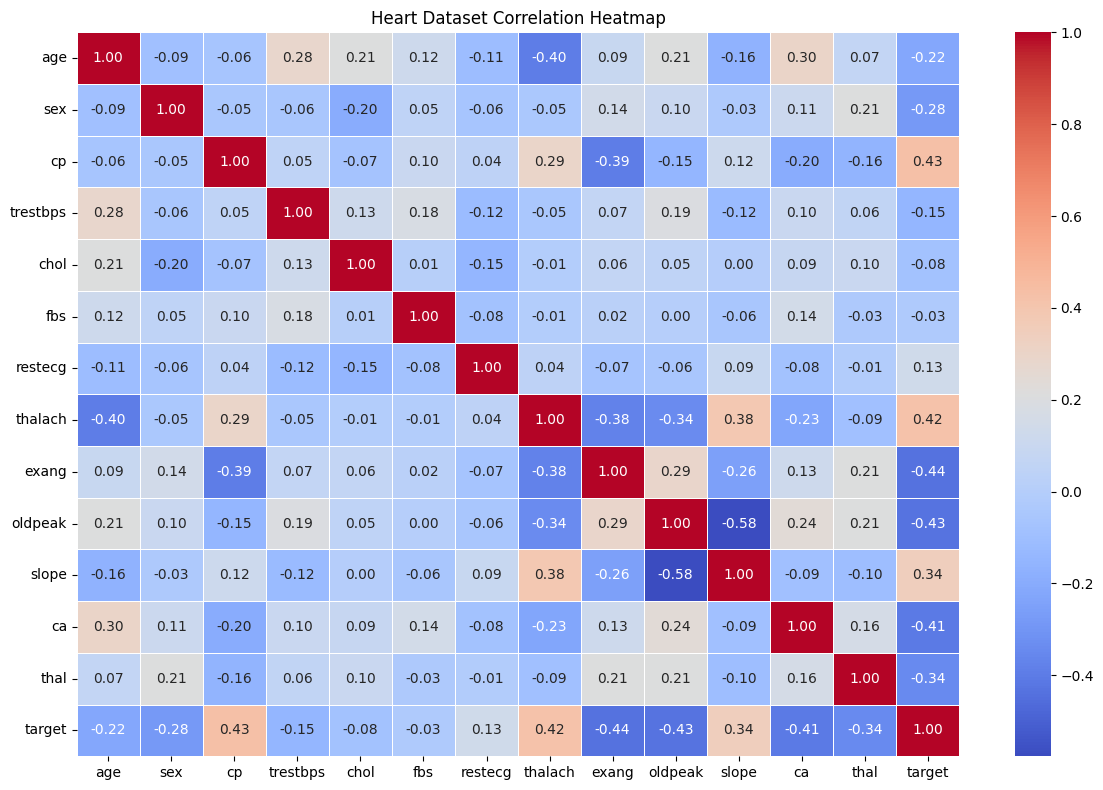

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
correlation = df.corr(numeric_only=True)

print("Correlation with target:")
print(correlation["target"].sort_values(ascending=False))
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Heart Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
X = df.drop("target", axis=1)
y = df["target"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Classes:")
print(y.value_counts())

Input Features Shape: (302, 13)
Target Shape: (302,)

Target Classes:
target
1    164
0    138
Name: count, dtype: int64


In [ ]:
# 2. Split data: train, validation, test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.36, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=5/9,
    random_state=42, stratify=y_temp
)

In [ ]:
# 3. Select top 5 features using training data only
selector = RandomForestClassifier(
    n_estimators=300, random_state=42
)
selector.fit(X_train, y_train)

importance = pd.Series(
    selector.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

top4 = importance.head(4).index.tolist()

print("Selected 3 features:", top4)

Selected 3 features: ['cp', 'thalach', 'thal', 'ca']


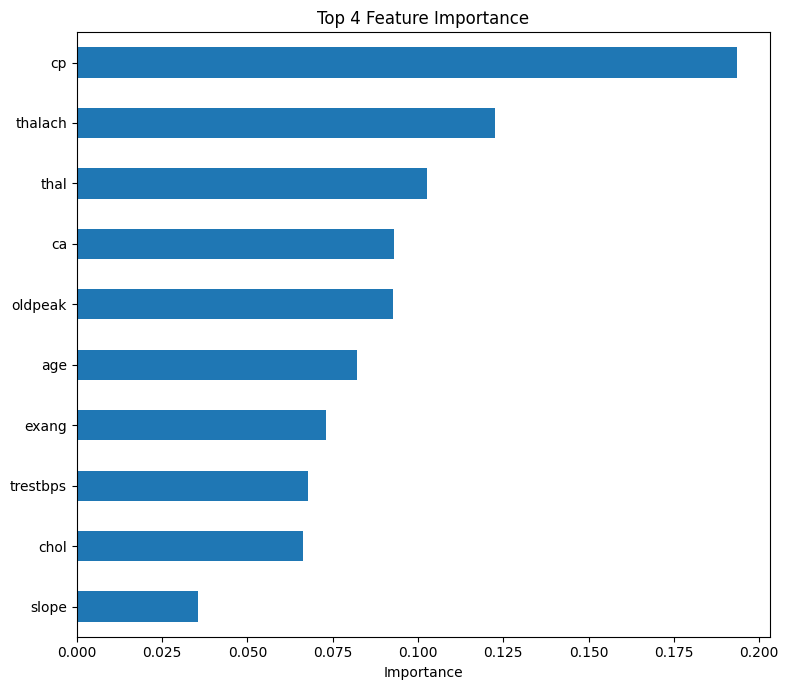

In [ ]:
# Feature importance visualization
importance.head(10).sort_values().plot(
    kind='barh', figsize=(8, 7)
)
plt.title("Top 4 Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [ ]:
# 4. ANN training function
def train_ann(features, epochs=100):
    scaler = StandardScaler()

    xtr = scaler.fit_transform(X_train[features])
    xval = scaler.transform(X_val[features])
    xte = scaler.transform(X_test[features])

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = Sequential([
        Input(shape=(len(features),)),
        Dense(32, activation='relu'),
        Dropout(0.2),
        Dense(16, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler

def train_ann(features, epochs=100):
    scaler = StandardScaler()
    xtr = scaler.fit_transform(X_train[features])
    xval = scaler.transform(X_val[features])
    xte = scaler.transform(X_test[features])

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = Sequential([
        Input(shape=(len(features),)),
        Dense(32, activation='relu'),
        Dropout(0.2),
        Dense(16, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        xtr, y_train,
        validation_data=(xval, y_val),
        epochs=epochs,
        batch_size=32,
        verbose=1
    )

    test_loss, test_acc = model.evaluate(
        xte, y_test, verbose=0
    )

    return model, history, scaler, test_acc, test_loss

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler

def train_ann(features, epochs=100):
    scaler = StandardScaler()
    xtr = scaler.fit_transform(X_train[features])
    xval = scaler.transform(X_val[features])
    xte = scaler.transform(X_test[features])

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = Sequential([
        Input(shape=(len(features),)),
        Dense(32, activation='relu'),
        Dropout(0.2),
        Dense(16, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        xtr, y_train,
        validation_data=(xval, y_val),
        epochs=epochs,
        batch_size=32,
        verbose=1
    )

    test_loss, test_acc = model.evaluate(
        xte, y_test, verbose=0
    )

    return model, history, scaler, test_acc, test_loss

In [ ]:
# 5. Train ANN using all features
model_all, hist_all, scaler_all, acc_all, loss_all = train_ann(
    X_train.columns.tolist()
)

# 6. Train ANN using selected 5 features
model_5, hist_5, scaler_5, acc_5, loss_5 = train_ann(top4)

# 7. Compare final test results
results = pd.DataFrame({
    'Model': ['ANN - All Features', 'ANN - Top 4 Features'],
    'Number of Features': [X.shape[1], 5],
    'Test Accuracy': [acc_all, acc_5],
    'Test Loss': [loss_all, loss_5]
})

print("\nModel Comparison:")
print(results.to_string(index=False))

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.5389 - loss: 0.6976 - val_accuracy: 0.7917 - val_loss: 0.6169
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6218 - loss: 0.6571 - val_accuracy: 0.7500 - val_loss: 0.5964
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6736 - loss: 0.6151 - val_accuracy: 0.7917 - val_loss: 0.5794
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7513 - loss: 0.5925 - val_accuracy: 0.7917 - val_loss: 0.5650
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6891 - loss: 0.5836 - val_accuracy: 0.7708 - val_loss: 0.5525
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7461 - loss: 0.5448 - val_accuracy: 0.7500 - val_loss: 0.5410
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7461 - loss: 0.5440 - val_accuracy: 0.7500 - val_loss: 0.5309
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7824 - loss: 0.5231 - val_accuracy: 0.7500 - val_loss:

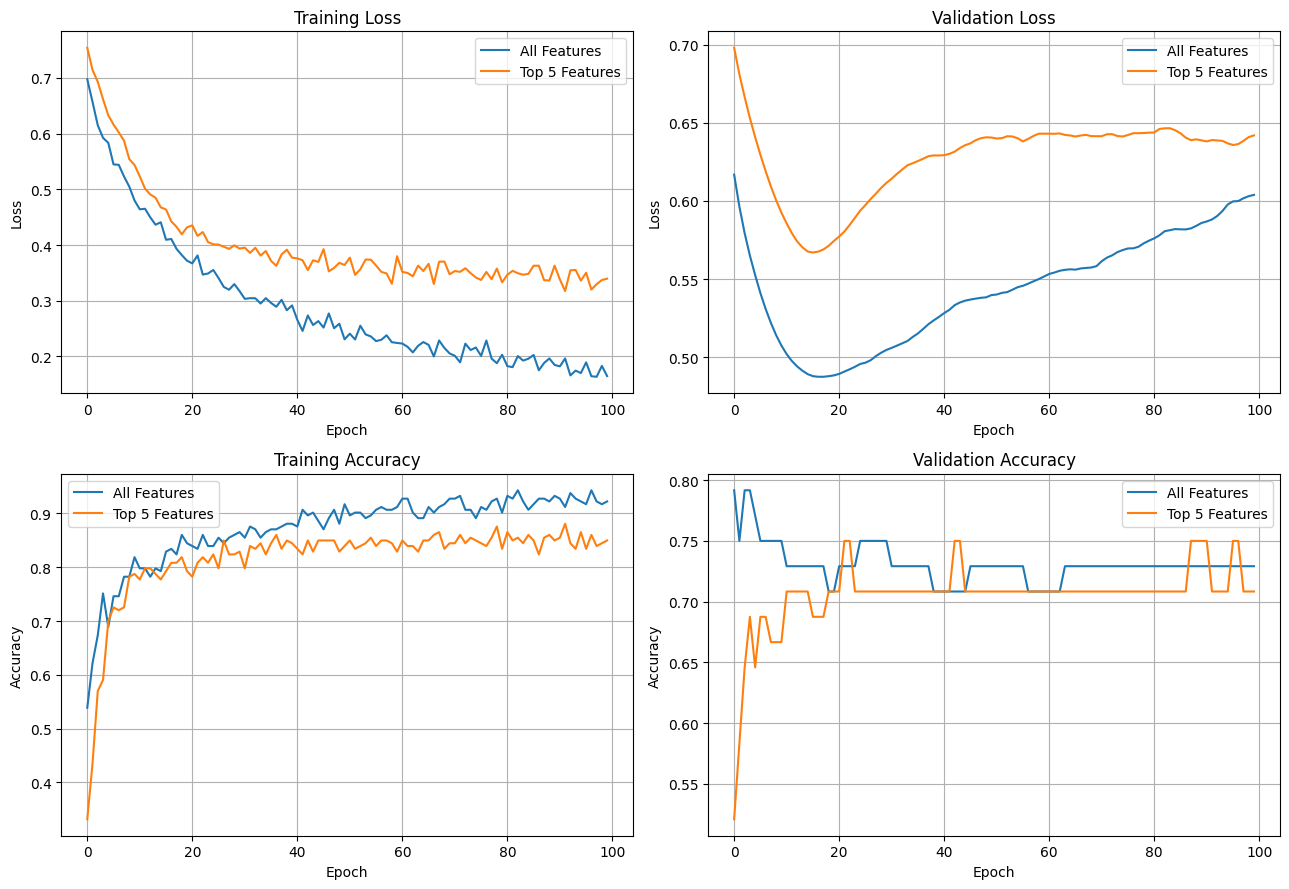

In [ ]:
# 8. Visualize loss and accuracy across epochs
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

histories = [
    (hist_all, 'All Features'),
    (hist_5, 'Top 5 Features')
]

for hist, name in histories:
    axes[0, 0].plot(hist.history['loss'], label=name)
    axes[0, 1].plot(hist.history['val_loss'], label=name)
    axes[1, 0].plot(hist.history['accuracy'], label=name)
    axes[1, 1].plot(hist.history['val_accuracy'], label=name)

axes[0, 0].set_title('Training Loss')
axes[0, 1].set_title('Validation Loss')
axes[1, 0].set_title('Training Accuracy')
axes[1, 1].set_title('Validation Accuracy')

for ax in axes.flat:
    ax.set_xlabel('Epoch')
    ax.grid(True)
    ax.legend()

axes[1, 0].set_ylabel('Accuracy')
axes[1, 1].set_ylabel('Accuracy')
axes[0, 0].set_ylabel('Loss')
axes[0, 1].set_ylabel('Loss')

plt.tight_layout()
plt.show()

In [ ]:
# 9. Classification report for the 5-feature model
x_test_4 = scaler_5.transform(X_test[top4])
predictions = (model_5.predict(x_test_4, verbose=0) >= 0.5).astype(int)

print("\nClassification Report - Top 5 Features:")
print(classification_report(y_test, predictions))


Classification Report - Top 5 Features:
              precision    recall  f1-score   support

           0       0.83      0.86      0.84        28
           1       0.88      0.85      0.86        33

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61

